# VCU Log Plotter

Run the helper cell once, then edit and run one of the three user-editable blocks. Change the `*_LOG_PATH` variable to the CSV log you want to inspect, and comment out individual parameter lines in `*_PARAMETERS` to control what gets plotted.

In [37]:
from pathlib import Path
import math
import re
import pandas as pd

from IPython.display import display
import matplotlib.pyplot as plt


def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "VCU").exists() and (path / "README.md").exists():
            return path
    return start


REPO_ROOT = find_repo_root()
_HEX_RE = re.compile(r"^0x[0-9a-fA-F]+$")


def resolve_log_path(log_path):
    path = Path(log_path).expanduser()
    if path.is_absolute():
        return path

    candidates = [
        Path.cwd() / path,
        REPO_ROOT / path,
        REPO_ROOT / "VCU" / path,
        Path.cwd().parent / path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    return (REPO_ROOT / path).resolve()


def read_vcu_log(log_path):
    path = resolve_log_path(log_path)
    if not path.exists():
        raise FileNotFoundError(f"Log file not found: {path}")

    df = pd.read_csv(path)
    if "t_ms" in df.columns:
        t_ms = pd.to_numeric(df["t_ms"], errors="coerce")
        first_t = t_ms.dropna().iloc[0] if t_ms.notna().any() else 0
        df.insert(1, "elapsed_s", (t_ms - first_t) / 1000.0)

    return df, path


def _coerce_for_plot(series):
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().any():
        return numeric, None

    text = series.astype(str).str.strip()
    if text.map(lambda value: bool(_HEX_RE.match(value))).any():
        converted = text.map(
            lambda value: int(value, 16) if _HEX_RE.match(value) else math.nan
        )
        return converted, None

    categorical = series.astype("category")
    codes = pd.Series(categorical.cat.codes, index=series.index).replace(-1, math.nan)
    mapping = {
        int(code): str(label)
        for code, label in enumerate(categorical.cat.categories)
    }
    return codes, mapping


def plot_vcu_log(log_path, parameters, title=None, max_points=5000, show_head=True, xlim=None, ylim=None):
    """
    Plot VCU log data for specified parameters.
    
    Parameters
    ----------
    log_path : str or Path
        Path to the log file (relative to repo root or absolute).
    parameters : list of str
        Names of parameters to plot.
    title : str, optional
        Plot title. If None, uses the filename.
    max_points : int, optional
        Maximum number of points to plot per parameter. Default 5000.
    show_head : bool, optional
        Whether to display the first few rows of the dataframe. Default True.
    xlim : tuple of (float, float), optional
        Limits for the x-axis as (min, max). If None, auto-scales.
    ylim : tuple of (float, float), optional
        Limits for the y-axis as (min, max). Applied to all y-axes. If None, auto-scales.
    """
    df, path = read_vcu_log(log_path)
    parameters = [name for name in parameters if name]
    missing = [name for name in parameters if name not in df.columns]
    selected = [name for name in parameters if name in df.columns]

    if not selected:
        raise ValueError("No selected parameters were found in the log.")

    if missing:
        print("Skipped missing parameters:", ", ".join(missing))

    step = max(1, math.ceil(len(df) / max_points)) if max_points else 1
    plot_df = df.iloc[::step].copy()
    if "elapsed_s" in plot_df.columns:
        x = plot_df["elapsed_s"]
        x_label = "Elapsed time (s)"
    elif "t_ms" in plot_df.columns:
        x = pd.to_numeric(plot_df["t_ms"], errors="coerce")
        x_label = "t_ms"
    else:
        x = plot_df.index
        x_label = "Sample"

    left_axes = math.ceil(len(selected) / 2)
    right_axes = len(selected) // 2
    fig_width = min(36, max(12, 10 + 0.6 * len(selected)))
    fig, base_ax = plt.subplots(figsize=(fig_width, 7), constrained_layout=False)
    fig.subplots_adjust(
        left=min(0.32, 0.08 + 0.018 * max(0, left_axes - 1)),
        right=max(0.68, 0.92 - 0.018 * max(0, right_axes - 1)),
        bottom=0.22,
        top=0.9,
    )

    mappings = {}
    lines = []
    cmap = plt.get_cmap("tab20" if len(selected) <= 20 else "turbo")
    colors = [cmap(i / max(1, len(selected) - 1)) for i in range(len(selected))]
    
    axes = []  # Store all axes for limit application
    
    for index, name in enumerate(selected):
        ax = base_ax if index == 0 else base_ax.twinx()
        ax.patch.set_visible(False)
        axes.append(ax)

        side = "left" if index % 2 == 0 else "right"
        offset = 44 * (index // 2)
        if side == "left":
            ax.spines["left"].set_position(("outward", offset))
            ax.spines["left"].set_visible(True)
            ax.spines["right"].set_visible(False)
            ax.yaxis.set_label_position("left")
            ax.yaxis.tick_left()
        else:
            ax.spines["right"].set_position(("outward", offset))
            ax.spines["right"].set_visible(True)
            ax.spines["left"].set_visible(False)
            ax.yaxis.set_label_position("right")
            ax.yaxis.tick_right()

        color = colors[index]
        y, mapping = _coerce_for_plot(plot_df[name])
        line, = ax.plot(x, y, linewidth=1.0, color=color, label=name)
        lines.append(line)
        ax.set_ylabel(name, color=line.get_color())
        ax.tick_params(axis="y", colors=line.get_color(), labelsize=8)
        ax.spines[side].set_color(line.get_color())
        if mapping:
            mappings[name] = mapping

    base_ax.grid(True, alpha=0.25)
    base_ax.set_xlabel(x_label)
    base_ax.legend(
        lines,
        [line.get_label() for line in lines],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=min(4, len(lines)),
        frameon=False,
    )
    
    # Apply axis limits if provided
    if xlim is not None:
        base_ax.set_xlim(xlim)
    
    if ylim is not None:
        for ax in axes:
            ax.set_ylim(ylim)
    
    if title is None:
        title = path.name
    step_note = f"; plotted every {step} row" if step > 1 else ""
    fig.suptitle(f"{title} - {len(df):,} rows{step_note}", y=0.98)
    plt.show()

    print(f"Loaded: {path}")
    print(f"Selected parameters: {', '.join(selected)}")
    if mappings:
        print("Categorical mappings:")
        for name, mapping in mappings.items():
            pairs = ", ".join(f"{code}={label}" for code, label in mapping.items())
            print(f"  {name}: {pairs}")

    if show_head:
        display(df.head())

    return df

## User-Editable Block: Fast VCU Log

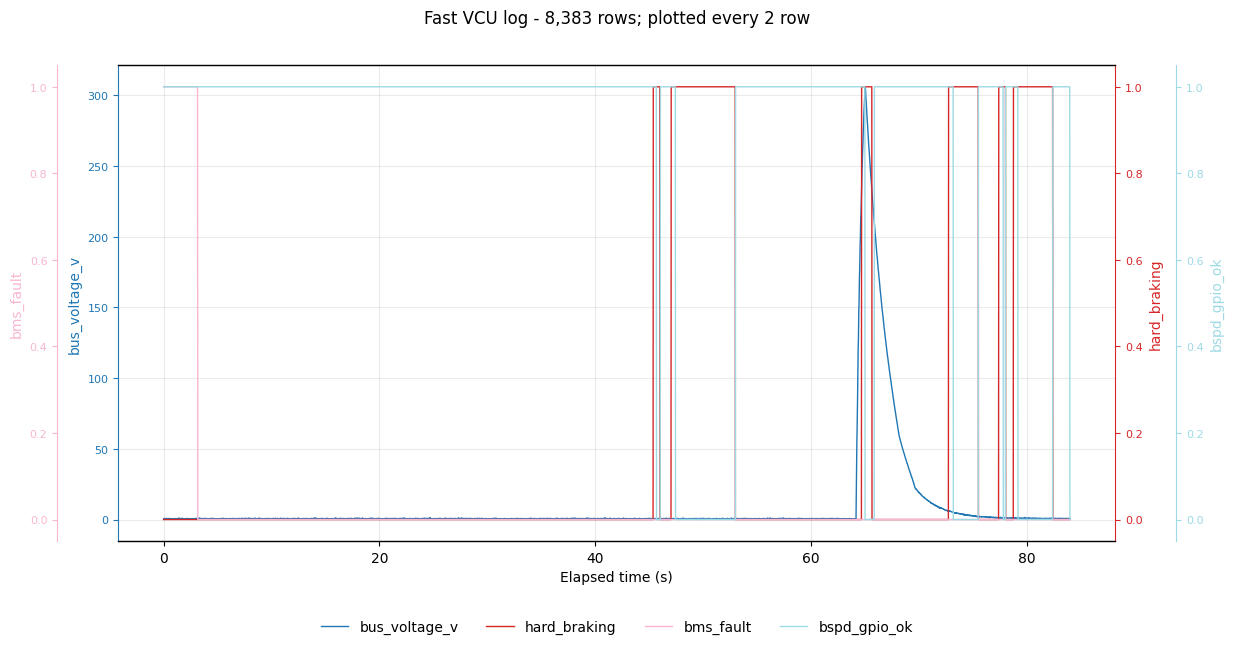

Loaded: C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery\LOG0008_fast.csv
Selected parameters: bus_voltage_v, hard_braking, bms_fault, bspd_gpio_ok


,t_ms,elapsed_s,raw_apps1,raw_apps2,raw_bse1,raw_bse2,raw_hv_current,commanded_torque_nm,motor_rpm,bus_voltage_v,...,drive_mode_d,bms_fault,imd_fault,pm100_fault,bms_timeout,imd_can_timeout,contactors_closed,bspd_gpio_ok,imd_gpio_ok,bms_gpio_ok
0,3275,0.000,2303,2194,452,482,1970,0.0,0,0.4,...,0,1,1,0,1,1,1,1,0,0
1,3286,0.011,2304,2195,452,483,1969,0.0,0,0.4,...,0,1,1,0,1,1,1,1,0,0
2,3296,0.021,2300,2195,452,482,1968,0.0,0,0.4,...,0,1,1,0,1,1,1,1,0,0
3,3306,0.031,2301,2195,452,484,1969,0.0,0,0.4,...,0,1,1,0,1,1,1,1,0,0
4,3316,0.041,2301,2195,452,483,1970,0.0,0,0.5,...,0,1,1,0,1,1,1,1,0,0


In [38]:
# USER EDIT BLOCK: fast VCU log
# Change FAST_LOG_PATH, then comment out any parameter lines you do not want plotted.
FAST_LOG_PATH = r"VCU/June11thTestingDataLog_AfterChargingBattery/LOG0008_fast.csv"

FAST_PARAMETERS = [
    # "t_ms",
    # "raw_apps1",
    # "raw_apps2",
    # "raw_bse1",
    # "raw_bse2",
    # "raw_hv_current",
    # "commanded_torque_nm",
    # "motor_rpm",
    "bus_voltage_v",
    # "bus_current_a",
    # "braking",
    "hard_braking",
    # "bspc_active",
    # "apps_plausible",
    # "rtd_latched",
    # "drive_mode_d",
    "bms_fault",
    # "imd_fault",
    # "pm100_fault",
    # "bms_timeout",
    # "imd_can_timeout",
    # "contactors_closed",
    "bspd_gpio_ok",
    # "imd_gpio_ok",
    # "bms_gpio_ok",
]

fast_df = plot_vcu_log(FAST_LOG_PATH, FAST_PARAMETERS, title="Fast VCU log")


## User-Editable Block: Medium VCU Log

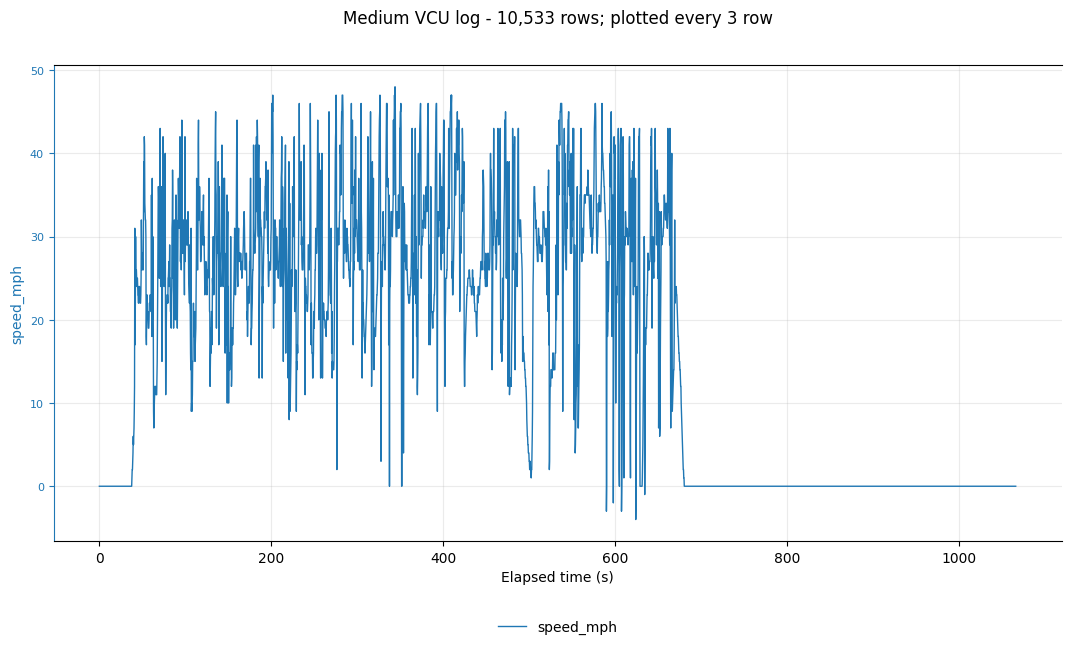

Loaded: C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery\LOG0012_medium.csv
Selected parameters: speed_mph


,t_ms,elapsed_s,apps1_pct,apps2_pct,pedal_pct,desired_torque_nm,power_kw,speed_mph,glv_voltage_v,inverter_temp_c,motor_temp_c,soc_pct,battery_temp_c,bms_flags_hex,bms_fault_code,imd_warn_alarms_hex,pm100_post_faults_hex,pm100_run_faults_hex,fan_duty_pct,rtd_state
0,3274,0.0,4.9,9.6,0.3,0.5,0.0,0,0.00,0.0,0.0,0,0,0x00,0,0x0000,0x00000000,0x00000000,20,FAULT_BLOCKED
1,3374,0.1,4.9,9.6,0.3,0.6,0.0,0,0.00,0.0,0.0,0,0,0x00,0,0x0000,0x00000000,0x00000000,20,FAULT_BLOCKED
2,3474,0.2,4.9,9.6,0.3,0.6,0.0,0,12.79,0.0,0.0,0,0,0x00,0,0x0000,0x00000000,0x00000000,20,FAULT_BLOCKED
3,3574,0.3,5.0,9.6,0.3,0.6,0.0,0,12.74,27.2,36.8,0,0,0x00,0,0x0000,0x00000000,0x00000000,83,FAULT_BLOCKED
4,3674,0.4,4.8,9.5,0.2,0.4,0.0,0,12.54,27.2,36.8,0,0,0x00,0,0x0000,0x00000000,0x00000000,83,FAULT_BLOCKED


In [44]:
# USER EDIT BLOCK: medium VCU log
# Change MEDIUM_LOG_PATH, then comment out any parameter lines you do not want plotted.
MEDIUM_LOG_PATH = r"VCU/June11thTestingDataLog_AfterChargingBattery/LOG0012_medium.csv"

MEDIUM_PARAMETERS = [
    # "t_ms",
    # "apps1_pct",
    # "apps2_pct",
    # "pedal_pct",
    # "desired_torque_nm",
    # "power_kw",
    "speed_mph",
    # "glv_voltage_v",
    # "inverter_temp_c",
    # "motor_temp_c",
    # "soc_pct",
    # "battery_temp_c",
    # "bms_flags_hex",
    # "bms_fault_code",
    # "imd_warn_alarms_hex",
    # "pm100_post_faults_hex",
    # "pm100_run_faults_hex",
    # "fan_duty_pct",
    # "rtd_state",
]

medium_df = plot_vcu_log(MEDIUM_LOG_PATH, MEDIUM_PARAMETERS, title="Medium VCU log")


## User-Editable Block: Slow VCU Log

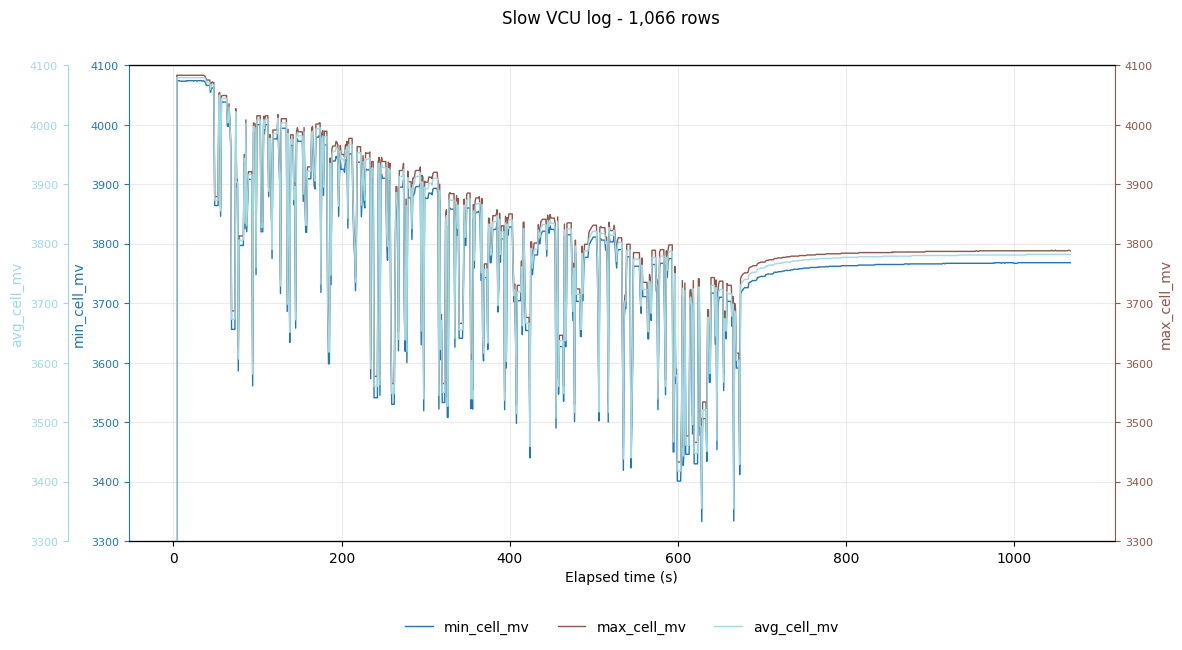

Loaded: C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery\LOG0012_slow.csv
Selected parameters: min_cell_mv, max_cell_mv, avg_cell_mv


,t_ms,elapsed_s,min_cell_mv,max_cell_mv,avg_cell_mv,min_cell_temp_c,max_cell_temp_c,avg_cell_temp_c,imd_riso_kohm,imd_riso_status,cell_v_valid,cell_t_valid,glv_valid
0,3274,0.0,0,0,0,-1000,-1000,-1000,65535,0,0,0,0
1,4274,1.0,0,0,0,-1000,-1000,-1000,5921,252,0,0,1
2,5274,2.0,0,0,0,-1000,-1000,-1000,8808,252,0,0,1
3,6274,3.0,0,0,0,-1000,-1000,-1000,10584,252,0,0,1
4,7274,4.0,4074,4083,4079,-1000,-1000,-1000,11639,252,1,0,1


In [43]:
# USER EDIT BLOCK: slow VCU log
# Change SLOW_LOG_PATH, then comment out any parameter lines you do not want plotted.
SLOW_LOG_PATH = r"VCU/June11thTestingDataLog_AfterChargingBattery/LOG0012_slow.csv"

SLOW_PARAMETERS = [
    # "t_ms",
    "min_cell_mv",
    "max_cell_mv",
    "avg_cell_mv",
    # "min_cell_temp_c",
    # "max_cell_temp_c",
    # "avg_cell_temp_c",
    # "imd_riso_kohm",
    # "imd_riso_status",
    # "cell_v_valid",
    # "cell_t_valid",
    # "glv_valid",
]

xlim = None
ylim = (3300, 4100)

slow_df = plot_vcu_log(SLOW_LOG_PATH, SLOW_PARAMETERS, title="Slow VCU log", xlim=xlim, ylim=ylim)


In [24]:
slow_df.tail()

,t_ms,elapsed_s,min_cell_mv,max_cell_mv,avg_cell_mv,min_cell_temp_c,max_cell_temp_c,avg_cell_temp_c,imd_riso_kohm,imd_riso_status,cell_v_valid,cell_t_valid,glv_valid
1061,1065554,1062.28,3768,3788,3782,32,41,36,37584,254,1,1,1
1062,1066554,1063.28,3768,3788,3782,32,41,36,37584,254,1,1,1
1063,1067554,1064.28,3768,3789,3782,32,41,36,37584,254,1,1,1
1064,1068554,1065.28,3768,3789,3782,32,41,36,37584,254,1,1,1
1065,1069554,1066.28,3768,3788,3782,32,41,36,37584,254,1,1,1


In [25]:
slow_df["max_cell_temp_c"].max()

42